In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
data=pd.read_csv("datos.csv")

In [4]:
data

,Sistema,Area,Generacion (MWh),Importacion Total (MWh),Exportacion Total (MWh),Intercambio neto entre Gerencias (MWh),Estimacion de Demanda por Balance (MWh),Pronostico (MWh),Timestamp
0,BCA,BCA,1124.16477,121.97846,220.99560,---,1025.14763,1006.009,01/01/2020 00:00
1,BCA,BCA,1053.94972,83.21267,131.53384,---,1005.62855,979.489,01/01/2020 01:00
2,BCA,BCA,1047.20819,107.04241,172.11608,---,982.13452,955.624,01/01/2020 02:00
3,BCA,BCA,1042.45775,115.12048,197.85693,---,959.72130,926.639,01/01/2020 03:00
4,BCA,BCA,1026.56176,114.05929,198.96707,---,941.65398,904.216,01/01/2020 04:00
...,...,...,...,...,...,...,...,...,...
373763,SIN,PEN,1690.08687,0.00000,54.47620,530.824,2166.43467,2413.661,30/09/2024 19:00
373764,SIN,PEN,1626.89274,0.00000,53.88127,593.09,2166.10147,2460.071,30/09/2024 20:00
373765,SIN,PEN,1627.05534,0.00000,54.37937,612.584,2185.25997,2512.388,30/09/2024 21:00
373766,SIN,PEN,1585.77332,0.00000,53.82536,646.254,2178.20197,2491.674,30/09/2024 22:00


In [5]:
time = data["Timestamp"]
time = pd.to_datetime(time, format="%d/%m/%Y %H:%M", dayfirst=True)
print(time)
#obteniendo los anios
years = time.dt.year.unique()
#agregando una columna con el anio
data["Year"] = time.dt.year
#obteniendo los meses
months = time.dt.month.unique()
#agregando una columna con el mes
data["Month"] = time.dt.month
#obteniendo los dias
days = time.dt.day.unique()
#agregando una columna con el dia
data["Day"] = time.dt.day
#obteniendo las horas
hours = time.dt.hour.unique()
#agregando una columna con la hora
data["Hour"] = time.dt.hour
#obteniendo los minutos
minutes = time.dt.minute.unique()
#agregando una columna con el minuto
data["Minute"] = time.dt.minute
#obteniendo los segundos
seconds = time.dt.second.unique()
#agregando una columna con el segundo
data["Second"] = time.dt.second
#obteniendo los microsegundos
microseconds = time.dt.microsecond.unique()
#agregando una columna con el microsegundo
data["Microsecond"] = time.dt.microsecond
#eliminando la columna Timestamp
#data.drop(columns=["Timestamp"], inplace=True)


0        2020-01-01 00:00:00
1        2020-01-01 01:00:00
2        2020-01-01 02:00:00
3        2020-01-01 03:00:00
4        2020-01-01 04:00:00
                 ...        
373763   2024-09-30 19:00:00
373764   2024-09-30 20:00:00
373765   2024-09-30 21:00:00
373766   2024-09-30 22:00:00
373767   2024-09-30 23:00:00
Name: Timestamp, Length: 373768, dtype: datetime64[us]


In [6]:
data["fecha_hora"] = pd.to_datetime(data[["Year", "Month", "Day", "Hour"]])
agrupado = data.groupby(["fecha_hora", "Area"])["Generacion (MWh)"].sum().reset_index()
print(agrupado)

                fecha_hora Area  Generacion (MWh)
0      2020-01-01 00:00:00  BCA        1124.16477
1      2020-01-01 00:00:00  BCS         211.12325
2      2020-01-01 00:00:00  CEN        1815.20269
3      2020-01-01 00:00:00  NES        7556.16709
4      2020-01-01 00:00:00  NOR        2700.33534
...                    ...  ...               ...
373763 2024-09-30 23:00:00  NOR        5102.64161
373764 2024-09-30 23:00:00  NTE        4248.61607
373765 2024-09-30 23:00:00  OCC        6206.21865
373766 2024-09-30 23:00:00  ORI        7588.07656
373767 2024-09-30 23:00:00  PEN        1552.78983

[373768 rows x 3 columns]


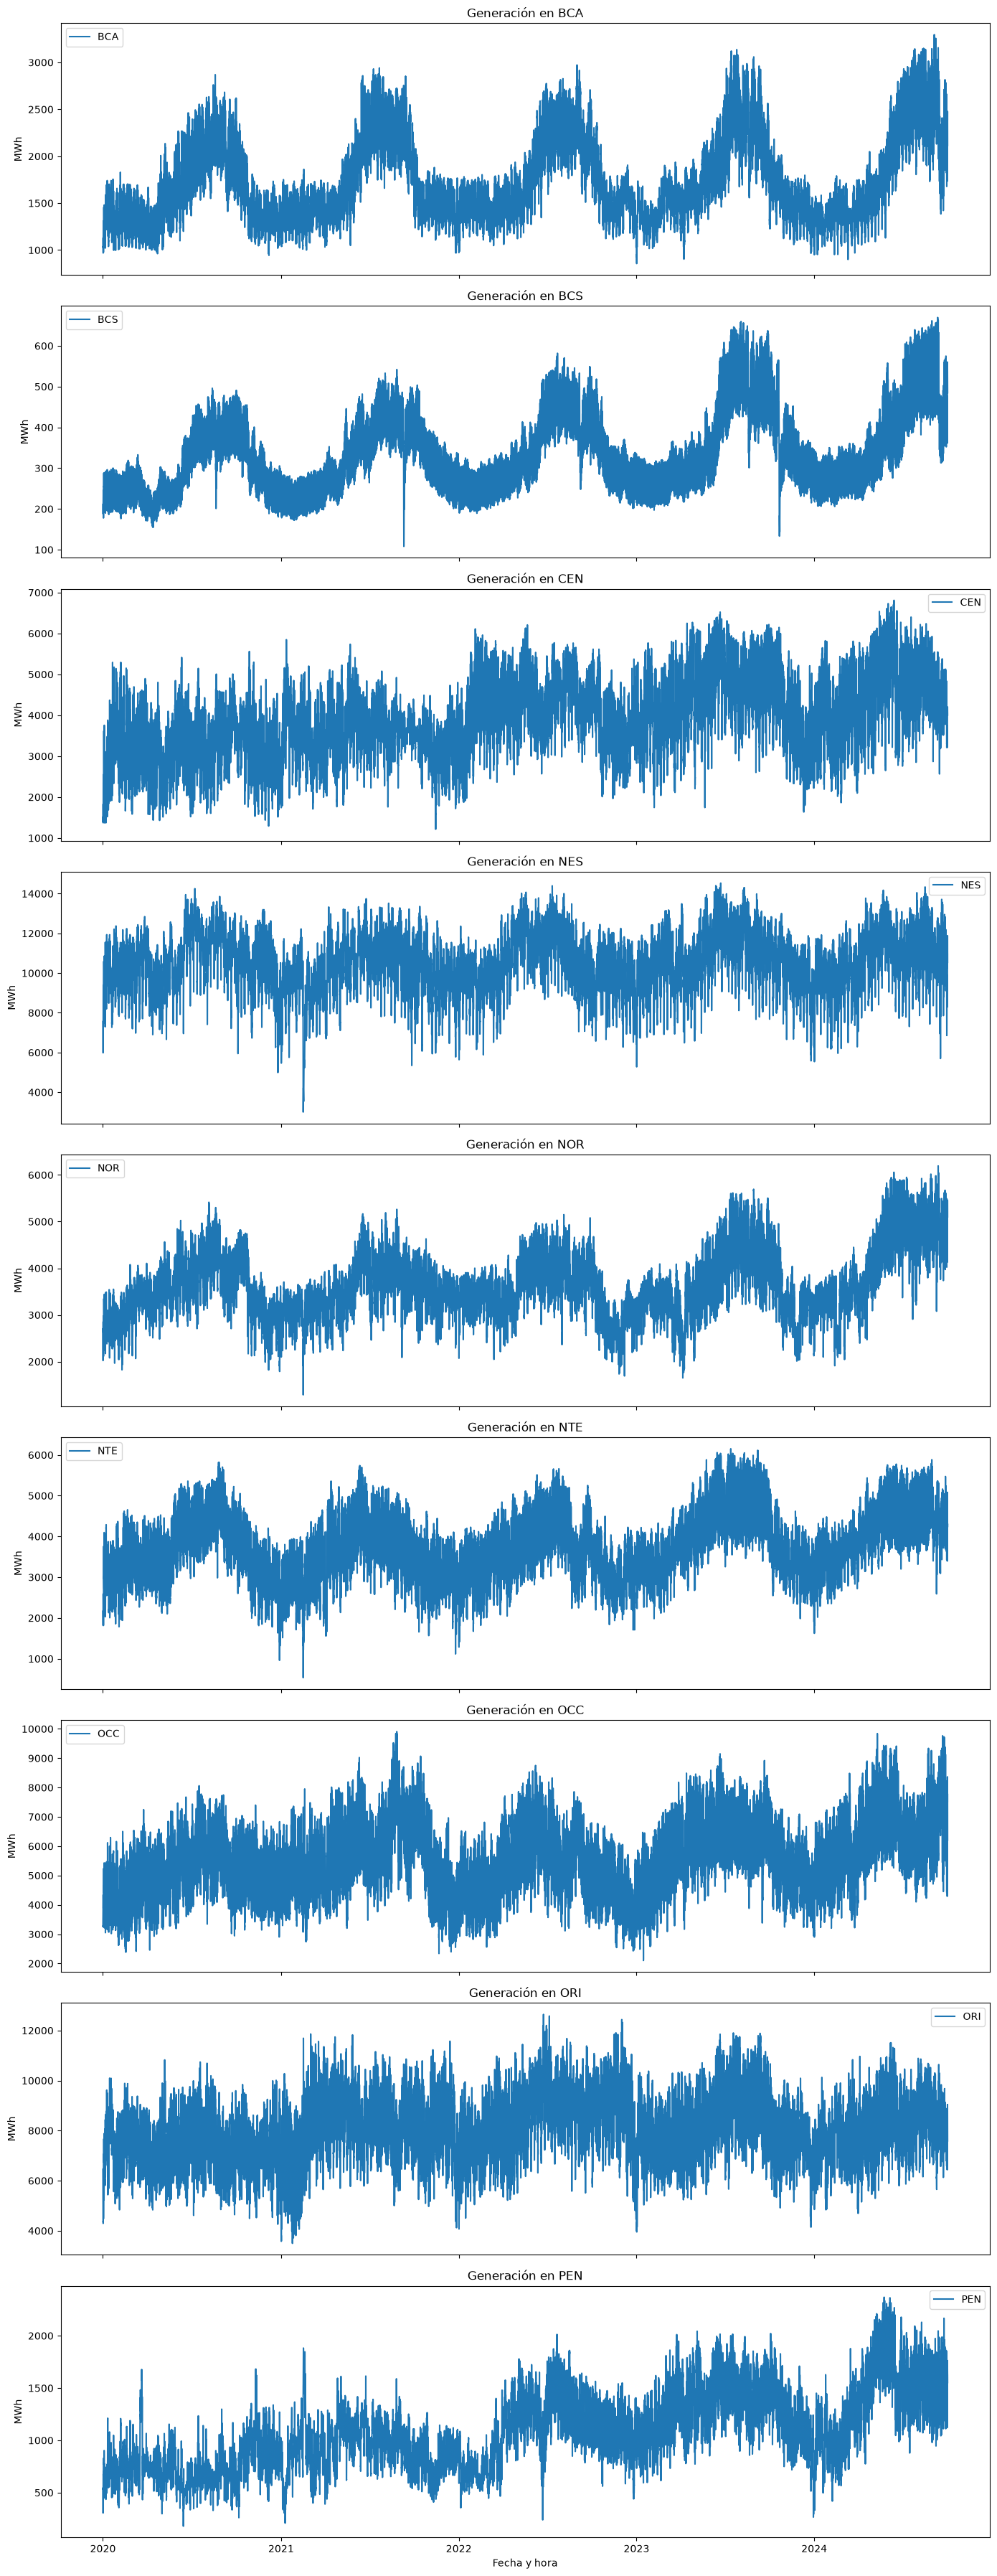

In [7]:
areas = agrupado["Area"].unique()
num_areas = len(areas)


fig, axs = plt.subplots(num_areas, 1, figsize=(14, 4 * num_areas), sharex=True)


if num_areas == 1:
    axs = [axs]


for i, area in enumerate(areas):
    subset = agrupado[agrupado["Area"] == area]
    axs[i].plot(subset["fecha_hora"], subset["Generacion (MWh)"], label=area)
    axs[i].set_title(f"Generación en {area}")
    axs[i].set_ylabel("MWh")
    axs[i].legend()

plt.xlabel("Fecha y hora")
plt.tight_layout()
plt.show()


                fecha_hora Area  Generacion (MWh)  Mediana_Movil_24h
0      2020-01-01 00:00:00  BCA        1124.16477         1124.16477
1      2020-01-01 00:00:00  BCS         211.12325          211.12325
2      2020-01-01 00:00:00  CEN        1815.20269         1815.20269
3      2020-01-01 00:00:00  NES        7556.16709         7556.16709
4      2020-01-01 00:00:00  NOR        2700.33534         2700.33534
...                    ...  ...               ...                ...
373763 2024-09-30 23:00:00  NOR        5102.64161         4778.32691
373764 2024-09-30 23:00:00  NTE        4248.61607         4098.46445
373765 2024-09-30 23:00:00  OCC        6206.21865         7301.01751
373766 2024-09-30 23:00:00  ORI        7588.07656         7858.41695
373767 2024-09-30 23:00:00  PEN        1552.78983         1581.97454

[373768 rows x 4 columns]


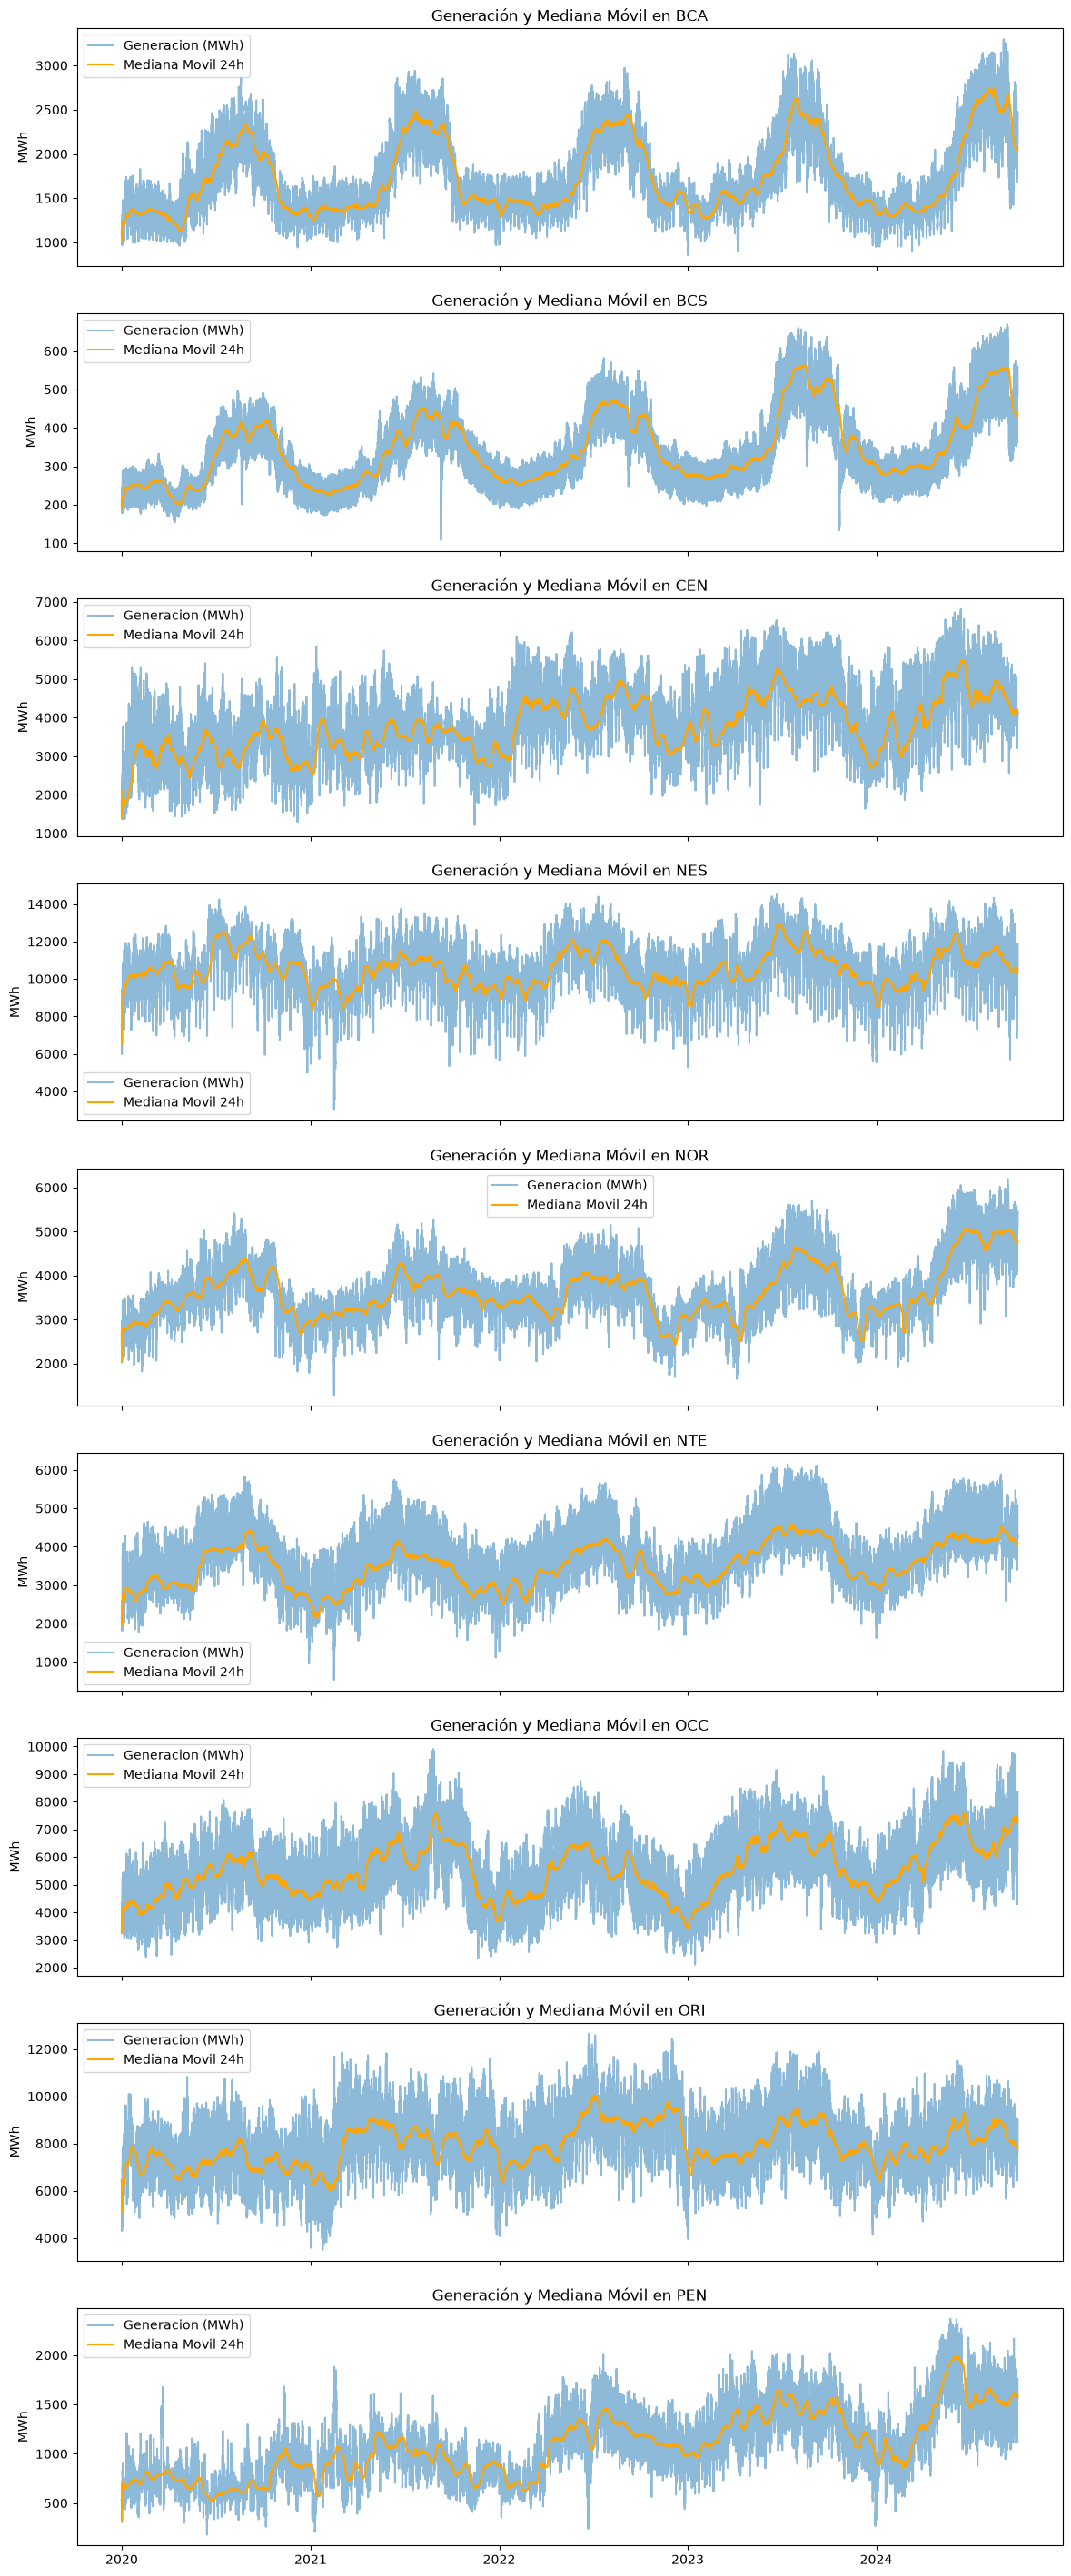

In [8]:
#filtro de mediana movil de 24 horas
agrupado["Mediana_Movil_24h"] = agrupado.groupby("Area")["Generacion (MWh)"].transform(lambda x: x.rolling(window=365, min_periods=1).median())
print(agrupado)
#graficando la mediana movil de 24 horas
fig, axs = plt.subplots(num_areas, 1, figsize=(14, 4 * num_areas), sharex=True)
if num_areas == 1:
    axs = [axs]
for i, area in enumerate(areas):
    subset = agrupado[agrupado["Area"] == area]
    axs[i].plot(subset["fecha_hora"], subset["Generacion (MWh)"], label="Generacion (MWh)", alpha=0.5)
    axs[i].plot(subset["fecha_hora"], subset["Mediana_Movil_24h"], label="Mediana Movil 24h", color='orange')
    axs[i].set_title(f"Generación y Mediana Móvil en {area}")
    axs[i].set_ylabel("MWh")
    axs[i].legend()

                fecha_hora Area  Generacion (MWh)  Mediana_Movil_24h  \
0      2020-01-01 00:00:00  BCA        1124.16477         1124.16477   
1      2020-01-01 00:00:00  BCS         211.12325          211.12325   
2      2020-01-01 00:00:00  CEN        1815.20269         1815.20269   
3      2020-01-01 00:00:00  NES        7556.16709         7556.16709   
4      2020-01-01 00:00:00  NOR        2700.33534         2700.33534   
...                    ...  ...               ...                ...   
373763 2024-09-30 23:00:00  NOR        5102.64161         4778.32691   
373764 2024-09-30 23:00:00  NTE        4248.61607         4098.46445   
373765 2024-09-30 23:00:00  OCC        6206.21865         7301.01751   
373766 2024-09-30 23:00:00  ORI        7588.07656         7858.41695   
373767 2024-09-30 23:00:00  PEN        1552.78983         1581.97454   

        Media_Exponencial  
0             1124.164770  
1              211.123250  
2             1815.202690  
3             7556.1670

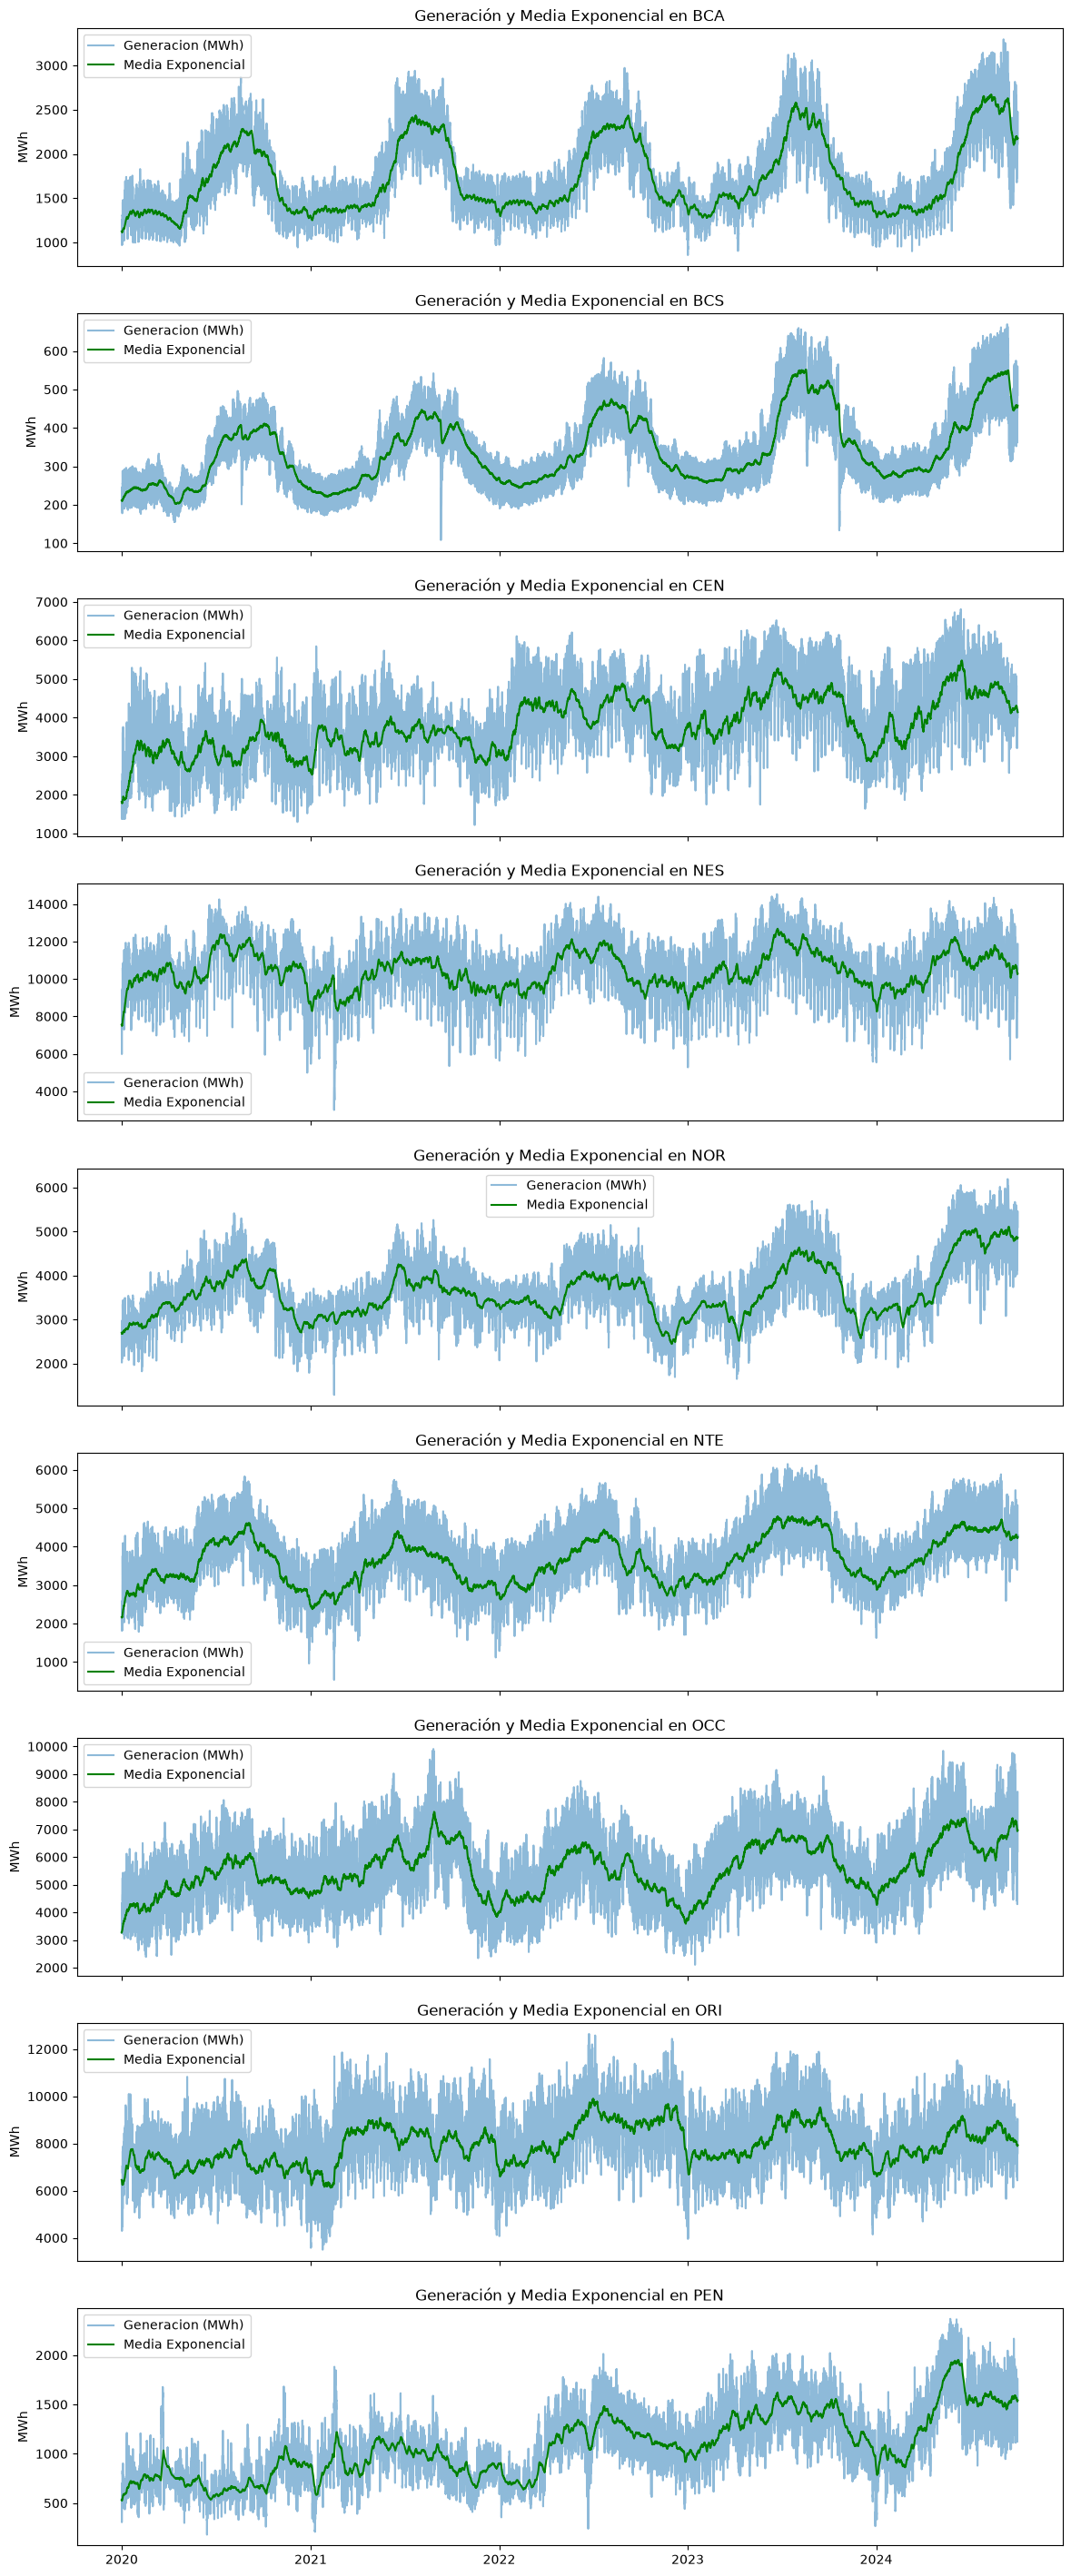

In [9]:
# filtrando con ventana exponencial
agrupado["Media_Exponencial"] = agrupado.groupby("Area")["Generacion (MWh)"].transform(lambda x: x.ewm(span=365, adjust=False).mean())
print(agrupado)
# graficando la media movil exponencial
fig, axs = plt.subplots(num_areas, 1, figsize=(14, 4 * num_areas), sharex=True)
if num_areas == 1:
    axs = [axs]
for i, area in enumerate(areas):
    subset = agrupado[agrupado["Area"] == area]
    axs[i].plot(subset["fecha_hora"], subset["Generacion (MWh)"], label="Generacion (MWh)", alpha=0.5)
    axs[i].plot(subset["fecha_hora"], subset["Media_Exponencial"], label="Media Exponencial", color='green')
    axs[i].set_title(f"Generación y Media Exponencial en {area}")
    axs[i].set_ylabel("MWh")
    axs[i].legend()

In [10]:
data.columns

Index(['Sistema', 'Area', 'Generacion (MWh)', 'Importacion Total (MWh)',
       'Exportacion Total (MWh)', 'Intercambio neto entre Gerencias (MWh)',
       'Estimacion de Demanda por Balance (MWh)', 'Pronostico (MWh)',
       'Timestamp', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'Second',
       'Microsecond', 'fecha_hora'],
      dtype='str')

In [11]:
agrupado.columns

Index(['fecha_hora', 'Area', 'Generacion (MWh)', 'Mediana_Movil_24h',
       'Media_Exponencial'],
      dtype='str')

In [12]:
#imprimiendo la longitud de la columna Media_Exponencial
print(agrupado['Media_Exponencial'].shape[0])
data['Media_Exponencial'] = agrupado['Media_Exponencial']
data.columns

373768


Index(['Sistema', 'Area', 'Generacion (MWh)', 'Importacion Total (MWh)',
       'Exportacion Total (MWh)', 'Intercambio neto entre Gerencias (MWh)',
       'Estimacion de Demanda por Balance (MWh)', 'Pronostico (MWh)',
       'Timestamp', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'Second',
       'Microsecond', 'fecha_hora', 'Media_Exponencial'],
      dtype='str')

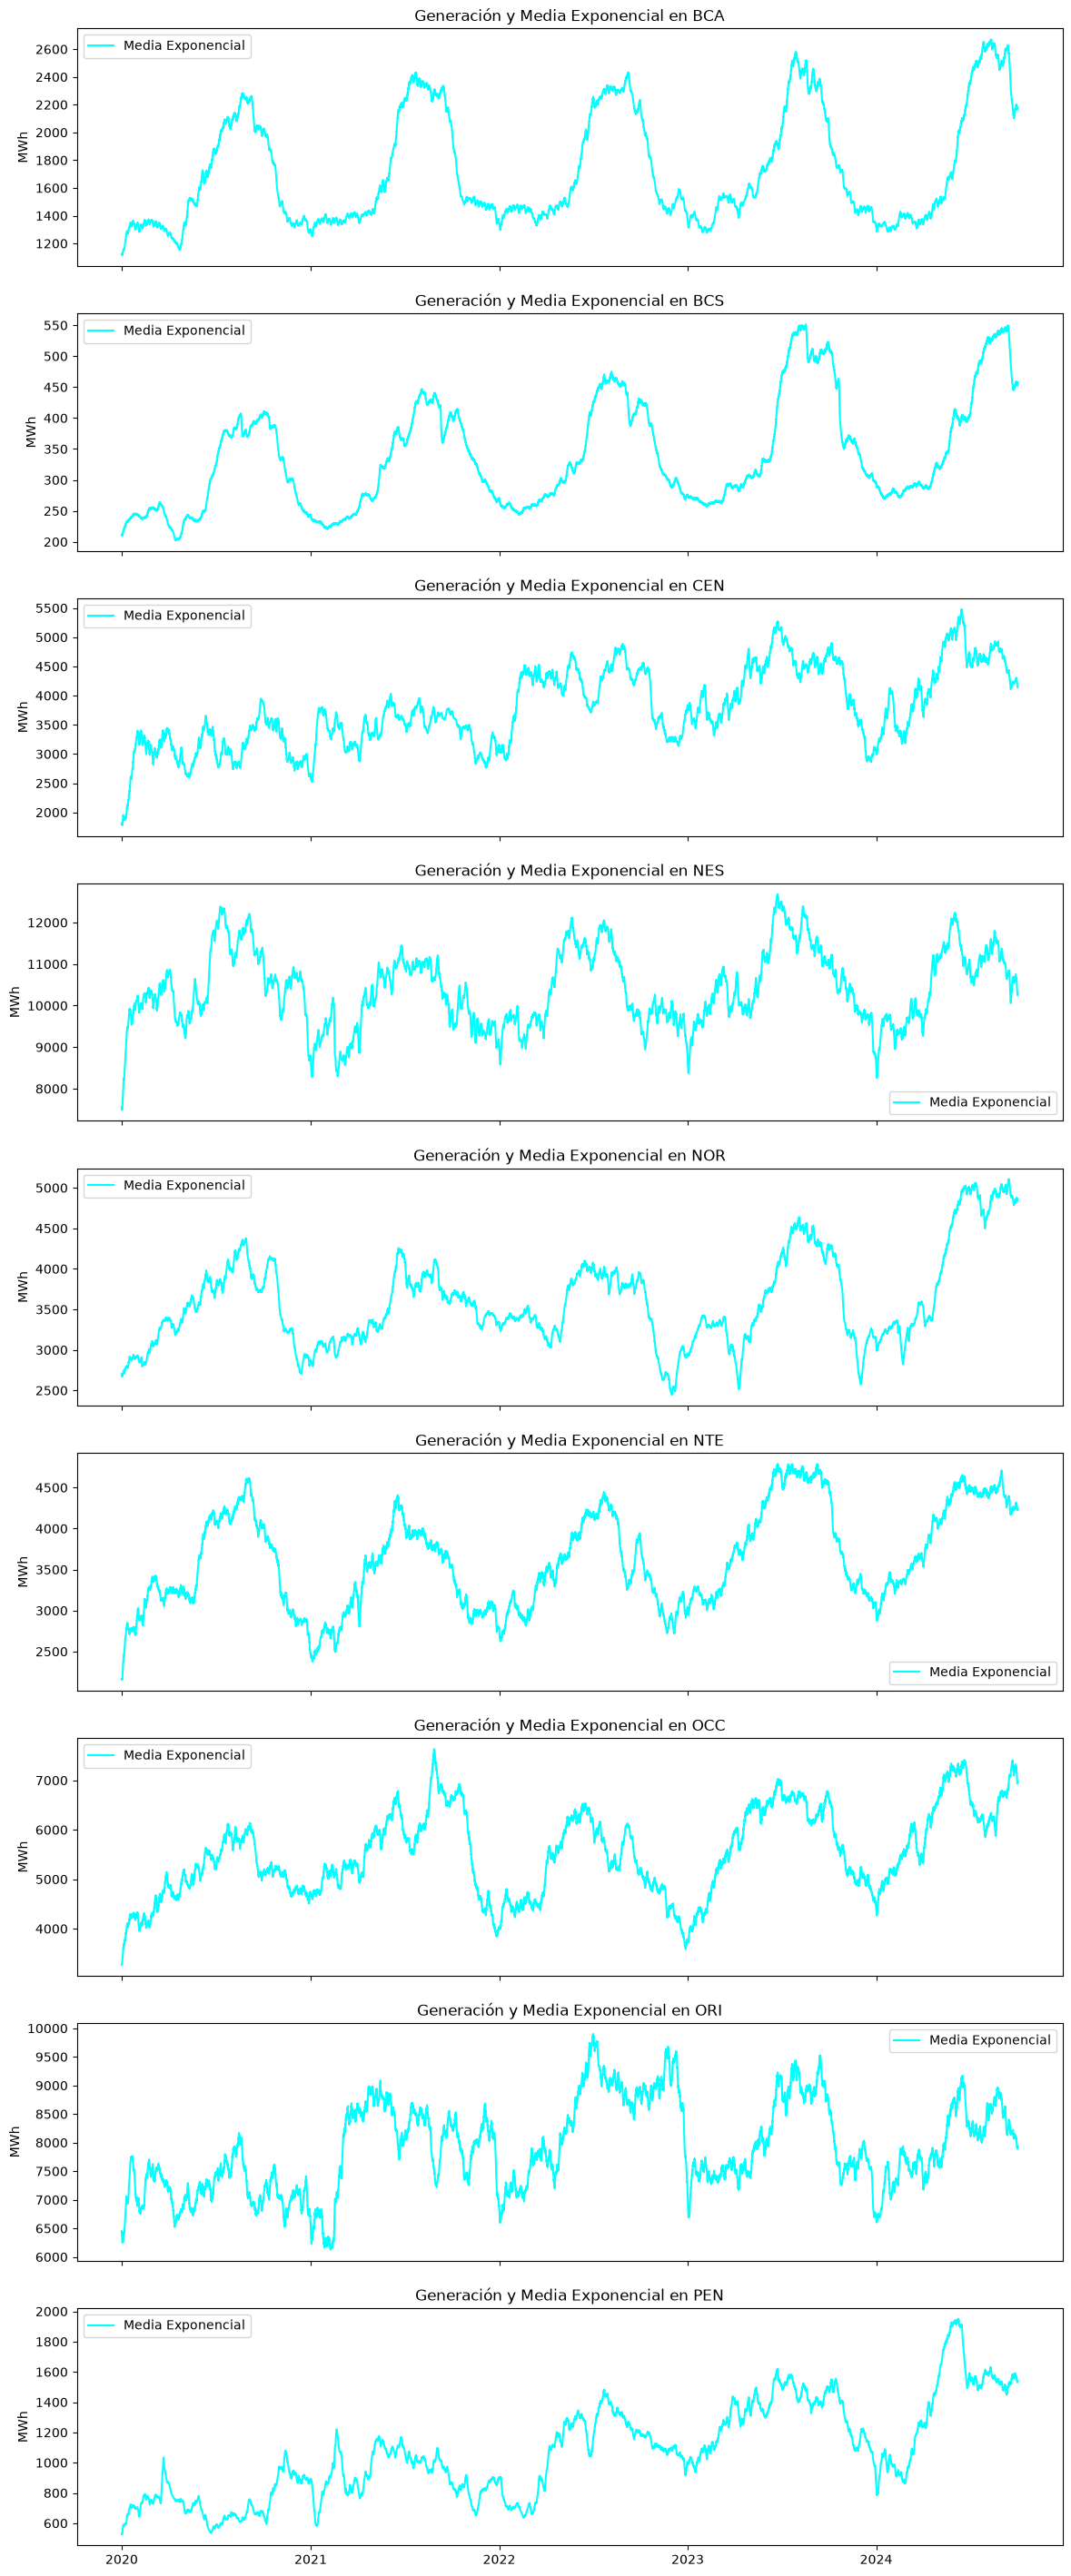

In [13]:
# graficando la media movil exponencial
fig, axs = plt.subplots(num_areas, 1, figsize=(14, 4 * num_areas), sharex=True)
if num_areas == 1:
    axs = [axs]
for i, area in enumerate(areas):
    subset = agrupado[agrupado["Area"] == area]
    axs[i].plot(subset["fecha_hora"], subset["Media_Exponencial"], label="Media Exponencial", color='cyan')
    axs[i].set_title(f"Generación y Media Exponencial en {area}")
    axs[i].set_ylabel("MWh")
    axs[i].legend()

In [14]:
data["fecha_hora"] = pd.to_datetime(data[["Year", "Month", "Day", "Hour"]])
agrupado = data.groupby(["fecha_hora", "Area"])["Generacion (MWh)"].sum().reset_index()

## Lasso

c:\Users\rulig\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.388947e+09, tolerance: 5.601e+06
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\rulig\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.442011e+09, tolerance: 5.601e+06
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\rulig\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

MSE: 10087587.18
R²: 0.00
Mejor alpha: 10.0

Últimos 12 valores reales utilizados como base:

                fecha_hora  Media_Exponencial
235330 2022-12-30 13:00:00        2928.053173
235331 2022-12-30 14:00:00        2993.227408
235332 2022-12-30 15:00:00        3763.330047
235333 2022-12-30 16:00:00        7445.630755
235334 2022-12-30 17:00:00         972.230514
235335 2022-12-30 18:00:00        1419.752388
235336 2022-12-30 19:00:00         274.534298
235337 2022-12-30 20:00:00        3746.797872
235338 2022-12-30 21:00:00        9031.363495
235339 2022-12-30 22:00:00        2927.854027
235340 2022-12-30 23:00:00        2993.402747
235533 2022-12-31 00:00:00        1401.023601


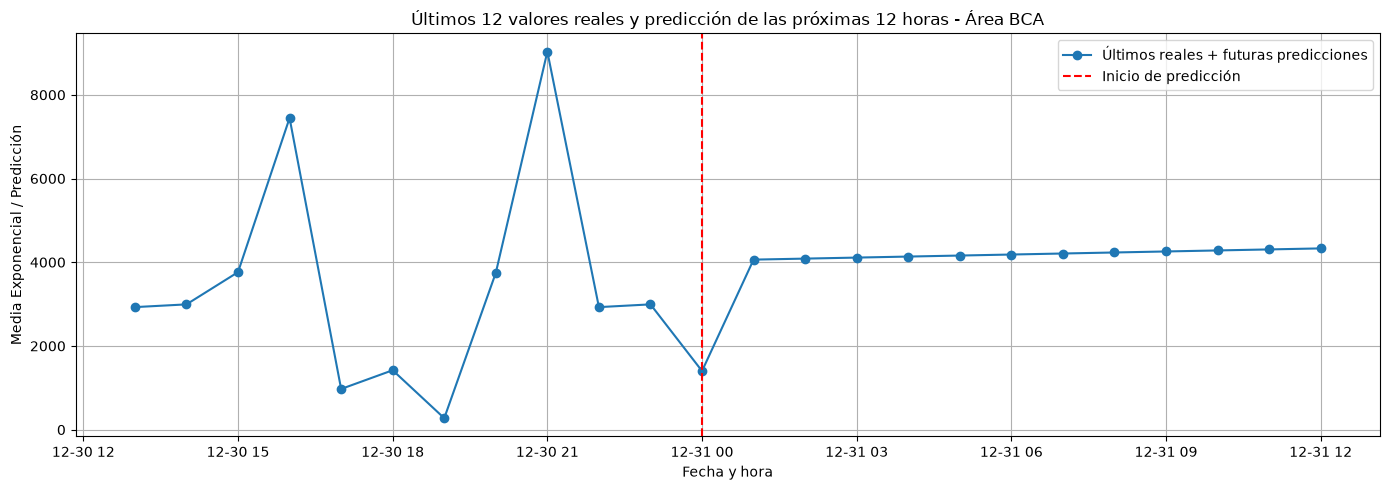

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday


fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Media_Exponencial'

X = data_periodo[features]
y = data_periodo[target]
fechas = data_periodo['fecha_hora']


X_train, X_test, y_train, y_test, fechas_train, fechas_test = train_test_split(
    X, y, fechas, test_size=0.2, random_state=42
)


model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'MSE: {mse:.2f}')
print(f'R²: {r2:.2f}')
print(f"Mejor alpha: {model.alpha_}")


resultados = pd.DataFrame({
    'fecha': fechas_test,
    'y_real': y_test,
    'y_pred': y_pred
}).sort_values('fecha')

ultimos_12 = data_periodo.tail(12).copy()
print("\nÚltimos 12 valores reales utilizados como base:\n")
print(ultimos_12[['fecha_hora', 'Media_Exponencial']])

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='h')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = future_df[['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']]

y_future_pred = model.predict(X_future)

# Combinar últimos reales + futuras predicciones
continuidad = pd.concat([
    ultimos_12[['fecha_hora', 'Media_Exponencial']].rename(columns={'Media_Exponencial': 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel('Media Exponencial / Predicción')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### LASSO

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()

X_train = ultimos_12[features]
y_train = ultimos_12[target]


model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
model.fit(X_train, y_train)


y_pred_train = model.predict(X_train)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
print(f'MSE (entrenamiento con últimos 12): {mse:.2f}')
print(f'R² (entrenamiento con últimos 12): {r2:.2f}')
print(f"Mejor alpha: {model.alpha_}")

print("\nÚltimos 12 valores reales utilizados como base:\n")
print(ultimos_12[['fecha_hora', target]])


ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = future_df[features]
y_future_pred = model.predict(X_future)


continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)


plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


MSE (entrenamiento con últimos 12): 3611.76
R² (entrenamiento con últimos 12): 0.13
Mejor alpha: 10.0

Últimos 12 valores reales utilizados como base:

                fecha_hora  Generacion (MWh)
235330 2022-12-30 13:00:00        1255.26019
235331 2022-12-30 14:00:00        1249.89125
235332 2022-12-30 15:00:00        1250.48770
235333 2022-12-30 16:00:00        1328.75954
235334 2022-12-30 17:00:00        1361.38550
235335 2022-12-30 18:00:00        1371.55009
235336 2022-12-30 19:00:00        1363.13821
235337 2022-12-30 20:00:00        1357.47125
235338 2022-12-30 21:00:00        1336.88348
235339 2022-12-30 22:00:00        1230.45696
235340 2022-12-30 23:00:00        1198.73968
235533 2022-12-31 00:00:00        1198.95243


ValueError: Invalid frequency: H. Failed to parse with error message: ValueError("Invalid frequency: H. Failed to parse with error message: KeyError('H'). Did you mean h?") Did you mean h?

### Ridge

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()

X_train = ultimos_12[features]
y_train = ultimos_12[target]


model = RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10])
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
print(f'MSE (entrenamiento con últimos 12): {mse:.2f}')
print(f'R² (entrenamiento con últimos 12): {r2:.2f}')
print(f"Mejor alpha: {model.alpha_}")

print("\nÚltimos 12 valores reales utilizados como base:\n")
print(ultimos_12[['fecha_hora', target]])

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = future_df[features]
y_future_pred = model.predict(X_future)

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### OLS

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

model = LinearRegression()
model.fit(X_scaled, y_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)
cv_mse = -cross_val_score(model, X_scaled, y_train, scoring='neg_mean_squared_error', cv=kf)
cv_r2 = cross_val_score(model, X_scaled, y_train, scoring='r2', cv=kf)

y_pred_train = model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)


print("Coeficientes:")
for f, c in sorted(zip(features, model.coef_), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {f:<12} -> {c: .6f}")
print(f"\nIntercepto (bias): {model.intercept_:.6f}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MSE promedio (CV): {cv_mse.mean():.4f} ± {cv_mse.std():.4f}")
print(f"R² promedio (CV): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = model.predict(X_future)

y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Elastic Net

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

alphas = np.logspace(-4, 2, 50)
l1_ratios = np.linspace(0.1, 0.9, 9)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

model = ElasticNetCV(alphas=alphas, l1_ratio=l1_ratios, cv=kf, max_iter=10000, random_state=42)
model.fit(X_scaled, y_train)

y_pred_train = model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print("\nEvaluación del Modelo Elastic Net")
print("Coeficientes ordenados (mayor impacto):")
for f, c in sorted(zip(features, model.coef_), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {f:<12} -> {c: .6f}")
print(f"\nIntercepto (bias): {model.intercept_:.6f}")
print(f"Alpha óptimo: {model.alpha_:.6f}")
print(f"L1_ratio óptimo: {model.l1_ratio_:.2f}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Perceptron

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate='adaptive',
    max_iter=10000,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=50
)
mlp.fit(X_scaled, y_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)
cv_mse = -cross_val_score(mlp, X_scaled, y_train, scoring='neg_mean_squared_error', cv=kf)
cv_r2 = cross_val_score(mlp, X_scaled, y_train, scoring='r2', cv=kf)

y_pred_train = mlp.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print("\n Evaluación del Modelo Perceptrón Multicapa")
print(f"Capas ocultas: {mlp.hidden_layer_sizes}")
print(f"Función de activación: {mlp.activation}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MSE promedio (CV): {cv_mse.mean():.4f} ± {cv_mse.std():.4f}")
print(f"R² promedio (CV): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"Iteraciones realizadas: {mlp.n_iter_}")
print(f"Convergió: {mlp.n_iter_ < mlp.max_iter}")

plt.figure(figsize=(10, 4))
plt.plot(mlp.loss_curve_, label="Pérdida durante entrenamiento")
plt.title("Curva de convergencia del Perceptrón Multicapa")
plt.xlabel("Iteraciones")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = mlp.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Multicapa: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Multicapa: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Multicapa: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Multicapa

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

param_grid = {
    'hidden_layer_sizes': [(32,16), (64,32,16), (128,64,32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01],
}

mlp_base = MLPRegressor(
    solver='adam',
    max_iter=10000,
    early_stopping=True,
    random_state=42,
    n_iter_no_change=100
)

grid_search = GridSearchCV(
    estimator=mlp_base,
    param_grid=param_grid,
    scoring='r2',
    cv=kf,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_scaled, y_train)
best_model = grid_search.best_estimator_

print("\n=== MEJOR MODELO ENCONTRADO ===")
print(f"Capas ocultas: {best_model.hidden_layer_sizes}")
print(f"Función de activación: {best_model.activation}")
print(f"Alpha (regularización): {best_model.alpha}")
print(f"Tasa de aprendizaje inicial: {best_model.learning_rate_init}")
print(f"R² promedio (validación cruzada): {grid_search.best_score_:.4f}")

y_pred_train = best_model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print(f"\nMSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"Iteraciones: {best_model.n_iter_}")
print(f"Convergió: {best_model.n_iter_ < best_model.max_iter}")

if hasattr(best_model, 'loss_curve_'):
    plt.figure(figsize=(10, 4))
    plt.plot(best_model.loss_curve_, label="Pérdida durante entrenamiento")
    plt.title("Curva de convergencia del Perceptrón Multicapa (MLP)")
    plt.xlabel("Iteraciones")
    plt.ylabel("Pérdida (Loss)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = best_model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Forma 2

### Lasso

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()

X_train = ultimos_12[features]
y_train = ultimos_12[target]

model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f'MSE (entrenamiento con últimos 12): {mse:.2f}')
print(f'R² (entrenamiento con últimos 12): {r2:.2f}')
print(f'MAE (entrenamiento con últimos 12): {mae:.2f}')
print(f"Mejor alpha: {model.alpha_}")

print("\nÚltimos 12 valores reales utilizados como base:\n")
print(ultimos_12[['fecha_hora', target]])

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = future_df[features]
y_future_pred = model.predict(X_future)

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred)
mse_test = mean_squared_error(real_previos, y_future_pred)
r2_test = r2_score(real_previos, y_future_pred)

print(f'\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.2f}')
print(f'MSE (prueba – comparación con últimos 12 reales): {mse_test:.2f}')
print(f'R² (prueba – comparación con últimos 12 reales): {r2_test:.2f}')

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Ridge

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()

X_train = ultimos_12[features]
y_train = ultimos_12[target]

model = RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10])
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f'MSE (entrenamiento con últimos 12): {mse:.2f}')
print(f'R² (entrenamiento con últimos 12): {r2:.2f}')
print(f'MAE (entrenamiento con últimos 12): {mae:.2f}')
print(f"Mejor alpha: {model.alpha_}")

print("\nÚltimos 12 valores reales utilizados como base:\n")
print(ultimos_12[['fecha_hora', target]])

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = future_df[features]
y_future_pred = model.predict(X_future)

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred)
mse_test = mean_squared_error(real_previos, y_future_pred)
r2_test = r2_score(real_previos, y_future_pred)

print(f'\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.2f}')
print(f'MSE (prueba – comparación con últimos 12 reales): {mse_test:.2f}')
print(f'R² (prueba – comparación con últimos 12 reales): {r2_test:.2f}')

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Ols

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

model = LinearRegression()
model.fit(X_scaled, y_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)
cv_mse = -cross_val_score(model, X_scaled, y_train, scoring='neg_mean_squared_error', cv=kf)
cv_r2 = cross_val_score(model, X_scaled, y_train, scoring='r2', cv=kf)

y_pred_train = model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print("Coeficientes:")
for f, c in sorted(zip(features, model.coef_), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {f:<12} -> {c: .6f}")
print(f"\nIntercepto (bias): {model.intercept_:.6f}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")
print(f"MSE promedio (CV): {cv_mse.mean():.4f} ± {cv_mse.std():.4f}")
print(f"R² promedio (CV): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = model.predict(X_future)

y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.4f}")
print(f"MSE (prueba – comparación con últimos 12 reales): {mse_test:.4f}")
print(f"R² (prueba – comparación con últimos 12 reales): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'OLS mejorado: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Elastic Net

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

alphas = np.logspace(-4, 0, 40)
l1_ratios = np.linspace(0.05, 0.9, 10)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

model = ElasticNetCV(
    alphas=alphas,
    l1_ratio=l1_ratios,
    cv=kf,
    max_iter=20000,
    random_state=42
)
model.fit(X_scaled, y_train)

y_pred_train = model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print("\nEvaluación del Modelo Elastic Net Mejorado")
print("Coeficientes ordenados (mayor impacto):")
for f, c in sorted(zip(features, model.coef_), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {f:<12} -> {c: .6f}")
print(f"\nIntercepto (bias): {model.intercept_:.6f}")
print(f"Alpha óptimo: {model.alpha_:.6f}")
print(f"L1_ratio óptimo: {model.l1_ratio_:.2f}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.4f}")
print(f"MSE (prueba – comparación con últimos 12 reales): {mse_test:.4f}")
print(f"R² (prueba – comparación con últimos 12 reales): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Elastic Net: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Perceptron

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

mlp = MLPRegressor(
    hidden_layer_sizes=(),   # <-- PERCEPTRÓN SIMPLE
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate='adaptive',
    max_iter=20000,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=50
)
mlp.fit(X_scaled, y_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)
cv_mse = -cross_val_score(mlp, X_scaled, y_train, scoring='neg_mean_squared_error', cv=kf)
cv_r2 = cross_val_score(mlp, X_scaled, y_train, scoring='r2', cv=kf)

y_pred_train = mlp.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print("\nEvaluación del Perceptrón Simple")
print(f"Capas ocultas: {mlp.hidden_layer_sizes}")
print(f"Función de activación: {mlp.activation}")
print(f"MSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")
print(f"MSE promedio (CV): {cv_mse.mean():.4f} ± {cv_mse.std():.4f}")
print(f"R² promedio (CV): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"Iteraciones realizadas: {mlp.n_iter_}")
print(f"Convergió: {mlp.n_iter_ < mlp.max_iter}")

plt.figure(figsize=(10, 4))
plt.plot(mlp.loss_curve_, label="Pérdida durante entrenamiento")
plt.title("Curva de convergencia del Perceptrón Simple")
plt.xlabel("Iteraciones")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = mlp.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.4f}")
print(f"MSE (prueba – comparación con últimos 12 reales): {mse_test:.4f}")
print(f"R² (prueba – comparación con últimos 12 reales): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Simple: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Simple: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Perceptrón Simple: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Multicapa

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

param_grid = {
    'hidden_layer_sizes': [(32,16), (64,32,16), (128,64,32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01],
}

mlp_base = MLPRegressor(
    solver='adam',
    max_iter=10000,
    early_stopping=True,
    random_state=42,
    n_iter_no_change=100
)

grid_search = GridSearchCV(
    estimator=mlp_base,
    param_grid=param_grid,
    scoring='r2',
    cv=kf,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_scaled, y_train)
best_model = grid_search.best_estimator_

print("\n=== MEJOR MODELO ENCONTRADO ===")
print(f"Capas ocultas: {best_model.hidden_layer_sizes}")
print(f"Función de activación: {best_model.activation}")
print(f"Alpha (regularización): {best_model.alpha}")
print(f"Tasa de aprendizaje inicial: {best_model.learning_rate_init}")
print(f"R² promedio (validación cruzada): {grid_search.best_score_:.4f}")

y_pred_train = best_model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f"\nMSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")
print(f"Iteraciones: {best_model.n_iter_}")
print(f"Convergió: {best_model.n_iter_ < best_model.max_iter}")

if hasattr(best_model, 'loss_curve_'):
    plt.figure(figsize=(10, 4))
    plt.plot(best_model.loss_curve_, label="Pérdida durante entrenamiento")
    plt.title("Curva de convergencia del MLP Optimizado")
    plt.xlabel("Iteraciones")
    plt.ylabel("Pérdida (Loss)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = best_model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – comparación con últimos 12 reales): {mae_test:.4f}")
print(f"MSE (prueba – comparación con últimos 12 reales): {mse_test:.4f}")
print(f"R² (prueba – comparación con últimos 12 reales): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones suavizadas')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'MLP Avanzado: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### SVM

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.1, 0.5, 1],
    'kernel': ['rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

svr_base = SVR()

grid_search = GridSearchCV(
    estimator=svr_base,
    param_grid=param_grid,
    scoring='r2',
    cv=kf,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_scaled, y_train)
best_model = grid_search.best_estimator_

print("\n MODELO SVM ")
print(f"Kernel: {best_model.kernel}")
print(f"C: {best_model.C}")
print(f"Epsilon: {best_model.epsilon}")
print(f"Gamma: {best_model.gamma}")
print(f"R² promedio (CV): {grid_search.best_score_:.4f}")

y_pred_train = best_model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f"\nMSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = best_model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – últimos 12 reales vs predicción futura): {mae_test:.4f}")
print(f"MSE (prueba): {mse_test:.4f}")
print(f"R² (prueba): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones (SVM)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'SVM (SVR): Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'SVM (SVR): Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'SVM (SVR): Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Random Forest

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2],
    'max_features': ['auto', 'sqrt', 'log2']
}

rf_base = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=kf,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_scaled, y_train)
best_model = grid_search.best_estimator_

print("\n RANDOM FOREST ")
print(f"n_estimators: {best_model.n_estimators}")
print(f"max_depth: {best_model.max_depth}")
print(f"min_samples_split: {best_model.min_samples_split}")
print(f"min_samples_leaf: {best_model.min_samples_leaf}")
print(f"max_features: {best_model.max_features}")
print(f"R² promedio (cross-validation): {grid_search.best_score_:.4f}")

y_pred_train = best_model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f"\nMSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = best_model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – últimos 12 reales vs predicción): {mae_test:.4f}")
print(f"MSE (prueba): {mse_test:.4f}")
print(f"R² (prueba): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + predicción Random Forest')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Random Forest: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Random Forest: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Random Forest: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Gradient Boosting

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday']
target = 'Generacion (MWh)'

ultimos_12 = data_periodo.tail(12).copy()
X_train = ultimos_12[features]
y_train = ultimos_12[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kf = KFold(n_splits=min(5, len(X_train)), shuffle=True, random_state=42)

param_grid = {
    'n_estimators': [100, 200, 400],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.9, 1.0],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2]
}

gbr_base = GradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=gbr_base,
    param_grid=param_grid,
    cv=kf,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_scaled, y_train)
best_model = grid_search.best_estimator_

print("\n GRADIENT BOOSTING ")
print(f"n_estimators: {best_model.n_estimators}")
print(f"learning_rate: {best_model.learning_rate}")
print(f"max_depth: {best_model.max_depth}")
print(f"subsample: {best_model.subsample}")
print(f"min_samples_split: {best_model.min_samples_split}")
print(f"min_samples_leaf: {best_model.min_samples_leaf}")
print(f"R² promedio (CV): {grid_search.best_score_:.4f}")

y_pred_train = best_model.predict(X_scaled)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)

print(f"\nMSE (entrenamiento): {mse:.4f}")
print(f"R² (entrenamiento): {r2:.4f}")
print(f"MAE (entrenamiento): {mae:.4f}")

ultima_fecha = data_periodo['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60

X_future = scaler.transform(future_df[features])
y_future_pred = best_model.predict(X_future)
y_future_pred_smooth = pd.Series(y_future_pred).rolling(3, min_periods=1, center=True).mean()

real_previos = data_periodo.tail(12)[target].values
mae_test = mean_absolute_error(real_previos, y_future_pred_smooth)
mse_test = mean_squared_error(real_previos, y_future_pred_smooth)
r2_test = r2_score(real_previos, y_future_pred_smooth)

print(f"\nMAE (prueba – últimos 12 reales vs predicción): {mae_test:.4f}")
print(f"MSE (prueba): {mse_test:.4f}")
print(f"R² (prueba): {r2_test:.4f}")

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred_smooth})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + predicción (Gradient Boosting)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Gradient Boosting: Últimos 12 valores y predicción 12h - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([ultimo_mes[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', color='tab:blue', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Gradient Boosting: Último mes + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana = data_periodo[data_periodo['fecha_hora'] >= (data_periodo['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([ultima_semana[['fecha_hora', target]].rename(columns={target: 'valor'}), continuidad.tail(13)], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', color='tab:green', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio predicción')
plt.title(f'Gradient Boosting: Última semana + predicción - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

ultimos_13 = data_periodo_lag.tail(13).copy()

train_12 = ultimos_13.iloc[:-1].copy()   
test_1   = ultimos_13.iloc[-1:].copy()   

X_train = train_12[features]
y_train = train_12[target]

X_test = test_1[features]
y_test = test_1[target]

model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
model.fit(X_train, y_train)


y_pred_train = model.predict(X_train)

y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro")
print(f"Real: {float(y_test.values):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Lasso:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por LassoCV: {model.alpha_}")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

ultimos_13 = data_periodo_lag.tail(13).copy()

train_12 = ultimos_13.iloc[:-1].copy()
test_1 = ultimos_13.iloc[-1:].copy()

X_train = train_12[features]
y_train = train_12[target]

X_test = test_1[features]
y_test = test_1[target]

model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Lasso:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por LassoCV: {model.alpha_}")

ultimos_12 = data_periodo_lag.tail(12).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o', label='Últimos reales + futuras predicciones')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes_real = data_periodo_lag[data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))].copy()
ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana_real = data_periodo_lag[data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=7))].copy()
ultima_semana = pd.concat([
    ultima_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o', label='Datos reales + predicción')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], color='red', linestyle='--', label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Agregar las dos versiones, el de un dia y una semana.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday


fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


target = 'Generacion (MWh)'


data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']


ultimos_13 = data_periodo_lag.tail(13).copy()

train_12 = ultimos_13.iloc[:-1].copy()
test_1   = ultimos_13.iloc[-1:].copy()

X_train = train_12[features]
y_train = train_12[target]

X_test = test_1[features]
y_test = test_1[target]

alphas = [0.001, 0.01, 0.1, 1, 10]

model = RidgeCV(alphas=alphas, cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")


mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro")
print(f"Real: {float(y_test.values):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Ridge:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por RidgeCV: {model.alpha_}")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

ultimos_13 = data_periodo_lag.tail(13).copy()

train_12 = ultimos_13.iloc[:-1].copy()
test_1 = ultimos_13.iloc[-1:].copy()

X_train = train_12[features]
y_train = train_12[target]

X_test = test_1[features]
y_test = test_1[target]

alphas = [0.001, 0.01, 0.1, 1, 10]
model = RidgeCV(alphas=alphas, cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Ridge:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por RidgeCV: {model.alpha_}")

ultimos_12 = data_periodo_lag.tail(12).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o',
         label='Últimos reales + futuras predicciones (Ridge)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))
].copy()

ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o',
         label='Datos reales + predicción (Ridge)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (Ridge, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultima_semana_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=7))
].copy()

ultima_semana = pd.concat([
    ultima_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o',
         label='Datos reales + predicción (Ridge)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (Ridge, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday


fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


target = 'Generacion (MWh)'


data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

ultimos_13 = data_periodo_lag.tail(13).copy()

train_12 = ultimos_13.iloc[:-1].copy()
test_1 = ultimos_13.iloc[-1:].copy()

X_train = train_12[features]
y_train = train_12[target]

X_test = test_1[features]
y_test = test_1[target]


model = LinearRegression()
model.fit(X_train, y_train)


y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)


mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO (OLS)")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")


mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro (OLS)")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo OLS (LinearRegression):")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nIntercepto (beta_0) OLS: {model.intercept_:.4f}")


ultimos_12 = data_periodo_lag.tail(12).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=13, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_12[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o',
         label='Últimos reales + futuras predicciones (OLS)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Últimos 12 valores reales y predicción de las próximas 12 horas (OLS) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


ultimo_mes_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))
].copy()

ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o',
         label='Datos reales + predicción (OLS)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + predicción (OLS, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


ultima_semana_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=7))
].copy()

ultima_semana = pd.concat([
    ultima_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    continuidad.tail(13)
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultima_semana['fecha_hora'], ultima_semana['valor'], marker='o',
         label='Datos reales + predicción (OLS)')
plt.axvline(x=ultimos_12['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + predicción (OLS, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


target = 'Generacion (MWh)'
data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_week = 24 * 7  # 168 horas

ultimos_semana_mas1 = data_periodo_lag.tail(n_week + 1).copy()

train_week = ultimos_semana_mas1.iloc[:-1].copy()
test_1 = ultimos_semana_mas1.iloc[-1:].copy()

X_train = train_week[features]
y_train = train_week[target]

X_test = test_1[features]
y_test = test_1[target]


alphas = [0.001, 0.01, 0.1, 1, 10]
model = LassoCV(alphas=alphas, cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO (Lasso - ventana 1 semana)")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro (Lasso)")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Lasso:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por LassoCV: {model.alpha_}")

ultimos_semana_real = data_periodo_lag.tail(n_week).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=n_week + 1, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o',
         label='Última semana real + próxima semana predicha (Lasso)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + próxima semana (Lasso) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))
].copy()

pred_semana_df = pd.DataFrame({
    'fecha_hora': future_df['fecha_hora'],
    'valor': y_future_pred
})

ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pred_semana_df
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o',
         label='Datos reales + próxima semana predicha (Lasso)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + próxima semana (Lasso, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


target = 'Generacion (MWh)'
data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_week = 24 * 7  

ultimos_semana_mas1 = data_periodo_lag.tail(n_week + 1).copy()

train_week = ultimos_semana_mas1.iloc[:-1].copy()
test_1 = ultimos_semana_mas1.iloc[-1:].copy()

X_train = train_week[features]
y_train = train_week[target]

X_test = test_1[features]
y_test = test_1[target]

alphas = [0.001, 0.01, 0.1, 1, 10]
model = RidgeCV(alphas=alphas, cv=3)
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO (Ridge - ventana 1 semana)")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro (Ridge)")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Ridge:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por RidgeCV: {model.alpha_}")

ultimos_semana_real = data_periodo_lag.tail(n_week).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=n_week + 1, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o',
         label='Última semana real + próxima semana predicha (Ridge)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + próxima semana (Ridge) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ultimo_mes_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))
].copy()

pred_semana_df = pd.DataFrame({
    'fecha_hora': future_df['fecha_hora'],
    'valor': y_future_pred
})

ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pred_semana_df
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o',
         label='Datos reales + próxima semana predicha (Ridge)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + próxima semana (Ridge, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()


target = 'Generacion (MWh)'
data_periodo['Gen_lag1'] = data_periodo[target].shift(1)
data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_week = 24 * 7  

ultimos_semana_mas1 = data_periodo_lag.tail(n_week + 1).copy()

train_week = ultimos_semana_mas1.iloc[:-1].copy()
test_1 = ultimos_semana_mas1.iloc[-1:].copy()

X_train = train_week[features]
y_train = train_week[target]

X_test = test_1[features]
y_test = test_1[target]

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_rel_train = mae_train / y_train.mean() * 100
rmse_rel_train = rmse_train / y_train.mean() * 100
mape_train = np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100

print("\n ENTRENAMIENTO (OLS - ventana 1 semana)")
print(f"MAE: {mae_train:.2f}")
print(f"RMSE: {rmse_train:.2f}")
print(f"R²: {r2_train:.2f}")
print(f"MAE relativo: {mae_rel_train:.2f}%")
print(f"RMSE relativo: {rmse_rel_train:.2f}%")
print(f"MAPE: {mape_train:.2f}%")

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)

mae_rel_test = mae_test / y_test.mean() * 100
rmse_rel_test = rmse_test / y_test.mean() * 100

print("\n PRUEBA registro (OLS)")
print(f"Real: {float(y_test.values[0]):.2f}")
print(f"Predicho: {float(y_test_pred[0]):.2f}")
print(f"MAE: {mae_test:.2f}")
print(f"RMSE: {rmse_test:.2f}")
print(f"MAE relativo: {mae_rel_test:.2f}%")
print(f"RMSE relativo: {rmse_rel_test:.2f}%")


coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo OLS (LinearRegression):")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))
print(f"\nIntercepto (beta_0) OLS: {model.intercept_:.4f}")


ultimos_semana_real = data_periodo_lag.tail(n_week).copy()

ultima_fecha = data_periodo_lag['fecha_hora'].max()
proximas_horas = pd.date_range(ultima_fecha, periods=n_week + 1, freq='H')[1:]

future_df = pd.DataFrame({'fecha_hora': proximas_horas})
future_df['Hour'] = future_df['fecha_hora'].dt.hour
future_df['Minute'] = 0
future_df['Day_of_Year'] = future_df['fecha_hora'].dt.dayofyear
future_df['Year'] = future_df['fecha_hora'].dt.year
future_df['Month'] = future_df['fecha_hora'].dt.month
future_df['Weekday'] = future_df['fecha_hora'].dt.weekday
future_df['Hour_of_Day'] = future_df['Hour'] + future_df['Minute'] / 60.0

y_future_pred = []
gen_lag = data_periodo_lag[target].iloc[-1]

for i in range(len(future_df)):
    future_df.loc[i, 'Gen_lag1'] = gen_lag
    fila = future_df.loc[i, features].values.reshape(1, -1)
    y_hat = model.predict(fila)[0]
    y_future_pred.append(y_hat)
    gen_lag = y_hat

y_future_pred = np.array(y_future_pred)

continuidad = pd.concat([
    ultimos_semana_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pd.DataFrame({'fecha_hora': future_df['fecha_hora'], 'valor': y_future_pred})
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(continuidad['fecha_hora'], continuidad['valor'], marker='o',
         label='Última semana real + próxima semana predicha (OLS)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Última semana + próxima semana (OLS) - Área {area_seleccionada}')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


ultimo_mes_real = data_periodo_lag[
    data_periodo_lag['fecha_hora'] >= (data_periodo_lag['fecha_hora'].max() - pd.Timedelta(days=30))
].copy()

pred_semana_df = pd.DataFrame({
    'fecha_hora': future_df['fecha_hora'],
    'valor': y_future_pred
})

ultimo_mes = pd.concat([
    ultimo_mes_real[['fecha_hora', target]].rename(columns={target: 'valor'}),
    pred_semana_df
], ignore_index=True)

plt.figure(figsize=(14, 5))
plt.plot(ultimo_mes['fecha_hora'], ultimo_mes['valor'], marker='o',
         label='Datos reales + próxima semana predicha (OLS)')
plt.axvline(x=ultimos_semana_real['fecha_hora'].iloc[-1], linestyle='--',
            label='Inicio de predicción')
plt.title(f'Generación eléctrica - Último mes + próxima semana (OLS, Área {area_seleccionada})')
plt.xlabel('Fecha y hora')
plt.ylabel(target)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()
data_30 = data_periodo_lag.iloc[n_70:].copy()

window_size = 13

reales = []
predichos = []

plt.figure(figsize=(8, 5))

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    plt.clf()
    plt.plot(reales, color='blue', label='Real')
    plt.plot(predichos, color='orange', label='Predicho')
    plt.xlabel('Horas')
    plt.ylabel('(MWh)')
    plt.title('Predicción vs Real')
    plt.legend()
    plt.pause(0.05)

plt.show()

y_real = np.array(reales)
y_pred = np.array(predichos)

mse = mean_squared_error(y_real, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_real, y_pred)
r2 = r2_score(y_real, y_pred)

mae_rel = mae / y_real.mean() * 100
rmse_rel = rmse / y_real.mean() * 100
mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100

print("\nRESULTADOS GLOBALES (VENTANA MÓVIL 70%)")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")
print(f"MAE relativo: {mae_rel:.2f}%")
print(f"RMSE relativo: {rmse_rel:.2f}%")
print(f"MAPE: {mape:.2f}%")

coeficientes = pd.Series(model.coef_, index=features)
print("\nCoeficientes del modelo Lasso:")
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index))

print(f"\nMejor alpha seleccionado por LassoCV: {model.alpha_}")

"""

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

plt.figure(figsize=(8, 5))
plt.plot(reales, color='blue', label='Real')
plt.plot(predichos, color='orange', label='Predicho')
plt.xlabel('Horas')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real (Ventana móvil)')
plt.legend()
plt.show()

print("\nTABLA DE MÉTRICAS POR VENTANA")
print(df_metricas)

print("\nPROMEDIOS DE MÉTRICAS")
print(df_metricas[['MAE', 'RMSE', 'R2']].mean())

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

intervalo = 168

reales_plot = reales[::intervalo]
predichos_plot = predichos[::intervalo]

plt.figure(figsize=(10, 5))
plt.plot(reales_plot, color='blue', label='Real')
plt.plot(predichos_plot, color='orange', label='Predicho')
plt.xlabel('Tiempo')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real ')
plt.legend()
plt.show()

df_metricas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

intervalo = 5

reales_plot = reales[::intervalo]
predichos_plot = predichos[::intervalo]

plt.figure(figsize=(10, 5))
plt.plot(reales_plot, color='blue', label='Real')
plt.plot(predichos_plot, color='orange', label='Predicho')
plt.xlabel('Tiempo')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real')
plt.legend()
plt.show()

df_metricas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

intervalo = 168

reales_plot = reales[::intervalo]
predichos_plot = predichos[::intervalo]

plt.figure(figsize=(10, 5))
plt.plot(reales_plot, color='blue', label='Real')
plt.plot(predichos_plot, color='orange', label='Predicho')
plt.xlabel('Tiempo')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real (Ridge - Ventana móvil)')
plt.legend()
plt.show()

df_metricas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

intervalo = 168

reales_plot = reales[::intervalo]
predichos_plot = predichos[::intervalo]

plt.figure(figsize=(10, 5))
plt.plot(reales_plot, color='blue', label='Real')
plt.plot(predichos_plot, color='orange', label='Predicho')
plt.xlabel('Tiempo')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real')
plt.legend()
plt.show()

df_metricas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []
metricas = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = ElasticNetCV(
        alphas=[0.001, 0.01, 0.1, 1, 10],
        l1_ratio=[0.1, 0.5, 0.9],
        cv=3
    )
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

    mse = mean_squared_error(y_train, y_pred_train)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_train, y_pred_train)
    r2 = r2_score(y_train, y_pred_train)

    metricas.append({
        'Ventana': i + 1,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_metricas = pd.DataFrame(metricas)

intervalo = 5

reales_plot = reales[::intervalo]
predichos_plot = predichos[::intervalo]

plt.figure(figsize=(10, 5))
plt.plot(reales_plot, color='blue', label='Real')
plt.plot(predichos_plot, color='orange', label='Predicho')
plt.xlabel('Tiempo')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real (Elastic Net - Ventana móvil)')
plt.legend()
plt.show()

df_metricas


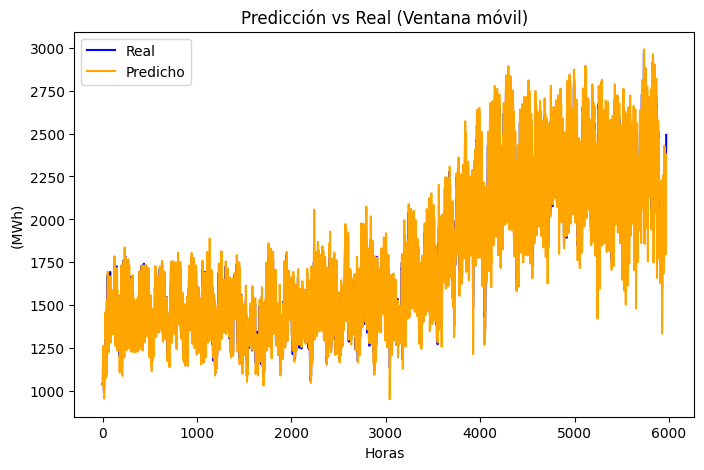


MÉTRICAS GLOBALES (SOBRE TODAS LAS PREDICCIONES)
MAE: 68.36
RMSE: 100.39
R²: 0.95


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

data['Hour_of_Day'] = data['Hour'] + data['Minute'] / 60.0
data['Day_of_Year'] = data['fecha_hora'].dt.dayofyear
data['Year'] = data['fecha_hora'].dt.year
data['Month'] = data['fecha_hora'].dt.month
data['Weekday'] = data['fecha_hora'].dt.weekday

fecha_inicio = '2022-01-01'
fecha_fin = '2022-12-31'
area_seleccionada = data['Area'].unique()[0]

data_periodo = data[
    (data['fecha_hora'] >= fecha_inicio) &
    (data['fecha_hora'] <= fecha_fin) &
    (data['Area'] == area_seleccionada)
].copy()

target = 'Generacion (MWh)'

data_periodo['Gen_lag1'] = data_periodo[target].shift(1)

data_periodo_lag = data_periodo.dropna(subset=['Gen_lag1']).copy()

features = ['Hour_of_Day', 'Day_of_Year', 'Year', 'Month', 'Weekday', 'Gen_lag1']

n_total = len(data_periodo_lag)
n_70 = int(n_total * 0.7)

data_70 = data_periodo_lag.iloc[:n_70].copy()

window_size = 13

reales = []
predichos = []

for i in range(len(data_70) - window_size + 1):
    ventana = data_70.iloc[i:i + window_size]
    train_12 = ventana.iloc[:-1]
    test_1 = ventana.iloc[-1:]

    X_train = train_12[features]
    y_train = train_12[target]

    X_test = test_1[features]
    y_test = test_1[target]

    model = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=3)
    model.fit(X_train, y_train)

    y_test_pred = model.predict(X_test)[0]

    reales.append(y_test.values[0])
    predichos.append(y_test_pred)

reales = np.array(reales)
predichos = np.array(predichos)

mae = mean_absolute_error(reales, predichos)
rmse = np.sqrt(mean_squared_error(reales, predichos))
r2 = r2_score(reales, predichos)

plt.figure(figsize=(8, 5))
plt.plot(reales, color='blue', label='Real')
plt.plot(predichos, color='orange', label='Predicho')
plt.xlabel('Horas')
plt.ylabel('(MWh)')
plt.title('Predicción vs Real (Ventana móvil)')
plt.legend()
plt.show()

print("\nMÉTRICAS GLOBALES (SOBRE TODAS LAS PREDICCIONES)")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")
